**Reduced feature set.** Copy of `3_methods/03_xgboost.ipynb` that leaves out the five features in `EXCLUDE_COLUMNS` (see `forecast_checks.py` in this folder and `../README.md`). The helper modules are the copies in this folder, and everything is read from and written to `results/` in this folder.

In [1]:
import pandas as pd
import xgboost as xgb
from sklearn.model_selection import GridSearchCV
from forecast_checks import (EXCLUDE_COLUMNS, ForecastValidator, MakeTrainingData, permutation_importance,
                             temperature_noise_sensitivity, save_tables)

In [2]:
SCORING_METRIC = "neg_mean_absolute_error"

In [3]:
trainer = MakeTrainingData(exclude_columns=EXCLUDE_COLUMNS)
data = trainer.get_train_test()
train_split = data["train"]
test_split=data["test"]
X_train, y_train = train_split["feature"], train_split["target"]
X_test, y_test = test_split["feature"], test_split["target"]

In [4]:
#Score every model on the same hours as 04_cnn.ipynb: drop test rows where a consumption lag is missing
scored = X_test.filter(like="consumption").notna().all(axis=1)
X_test, y_test = X_test[scored], y_test[scored]

In [5]:
#Hyperparameter tuning with CVGrid

NUM_TREES=[100,500,1000]
LEARNING_RATE=[0.025, 0.05, 0.075]
MAX_DEPTH=[5,10,15]

BASE_PARAMS = dict(enable_categorical=True, tree_method="hist", random_state=42)
param_grid = {"n_estimators": NUM_TREES, "learning_rate": LEARNING_RATE, "max_depth": MAX_DEPTH}
#Same three 2-week windows as 04_cnn.ipynb (late autumn and winter, like the test period), each fitted up to
#6 days before it. GridSearchCV wants row positions, validation_windows gives row labels
windows = MakeTrainingData.validation_windows(trainer.df.loc[X_train.index, "date"])
cv = [(X_train.index.get_indexer(fit), X_train.index.get_indexer(val)) for fit, val in windows]
search = GridSearchCV(xgb.XGBRegressor(**BASE_PARAMS), param_grid, cv=cv,
                      scoring=SCORING_METRIC, refit=False,
                      verbose=True)
search.fit(X_train, y_train)
print("Best params:", search.best_params_)

Fitting 3 folds for each of 27 candidates, totalling 81 fits


Best params: {'learning_rate': 0.075, 'max_depth': 5, 'n_estimators': 1000}


In [6]:
#TRAIN

model = xgb.XGBRegressor(**BASE_PARAMS, **search.best_params_)
model.fit(X_train, y_train)
pred = model.predict(X_test)

In [7]:
#TEST

forecastValidator = (ForecastValidator(y_test, groups=X_test["location"])
                     .add("Same hour last week", X_test["consumption_7days_ago"], baseline=True)
                     .add("XGBoost", pred))
forecastValidator.summary()

,mae,rmse,nmae,bias
Same hour last week,0.494720,0.806999,8.983281,0.033943
XGBoost,0.338576,0.538403,6.147963,0.162479


In [8]:
forecastValidator.save_to_json("results/xgboost.json")
forecastValidator.save_predictions("results/xgboost_predictions.json")

In [9]:
#Robustness on the test period, used by 07_error_analysis.ipynb. Importance: how much the MAE grows when a group of inputs
#is shuffled (same groups as 04_cnn.ipynb). The test period has no holidays, so holiday is part of calendar.
#Temperature noise: the error of a real day-ahead forecast, added to the temperature of the target hour
FEATURE_GROUPS = {"consumption": [c for c in X_test.columns if "consumption" in c],
                  "temperature": ["temperature"],
                  "calendar": ["hour", "weekday", "weekend", "holiday"],
                  "other weather": ["precipitation", "rain", "snowfall", "wind_speed_10m", "wind_direction_10m"]}
#Only the columns the model was trained on (EXCLUDE_COLUMNS are left out)
FEATURE_GROUPS = {group: [c for c in cols if c in X_test.columns] for group, cols in FEATURE_GROUPS.items()}
importance = permutation_importance(model.predict, X_test, y_test, FEATURE_GROUPS)
temperature_noise = temperature_noise_sensitivity(model.predict, X_test, y_test, trainer.df.loc[X_test.index, "date"],
                                                  ["temperature"])
save_tables("results/xgboost_robustness.json", importance=importance, temperature_noise=temperature_noise)
importance

,mae_increase,mae_increase_std,relative_increase
feature_group,,,
consumption,0.050568,0.001811,14.935389
temperature,0.193613,0.003625,57.184490
calendar,0.146216,0.001109,43.185721
other weather,0.001025,0.000348,0.302779


In [10]:
temperature_noise

,mae,mae_std,relative_increase
sigma,,,
0.0,0.338576,0.000000,0.000000
0.5,0.344356,0.001670,1.707192
1.0,0.352342,0.002754,4.065884
2.0,0.372939,0.010051,10.149197
3.0,0.390196,0.010002,15.246413


In [11]:
#Forecasts on the same three validation windows as 04_cnn.ipynb (they include Christmas and New Year, which the
#test period does not), for the holiday analysis in 07_error_analysis.ipynb. Same parameters, fitted up to 6 days before each window
val_X, val_pred = [], []
for fit, val in MakeTrainingData.validation_windows(trainer.df.loc[X_train.index, "date"]):
    val = val[X_train.loc[val].filter(like="consumption").notna().all(axis=1)]
    val_X.append(X_train.loc[val])
    val_pred.append(pd.Series(xgb.XGBRegressor(**BASE_PARAMS, **search.best_params_)
                              .fit(X_train.loc[fit], y_train.loc[fit]).predict(X_train.loc[val]), index=val))
val_X, val_pred = pd.concat(val_X), pd.concat(val_pred)
val_validator = (ForecastValidator(y_train.loc[val_X.index], groups=val_X["location"])
                 .add("Same hour last week", val_X["consumption_7days_ago"], baseline=True)
                 .add("XGBoost", val_pred))
val_validator.save_predictions("results/xgboost_validation_predictions.json")
val_validator.per_group(skill=True)

mae      rmse       nmae      bias  \
model               group                                                  
Same hour last week bergen       0.494656  0.571749  14.471781 -0.068834   
                    helsingfors  0.135916  0.178670   2.059390  0.007267   
                    oslo         2.342415  2.610506  17.462961 -0.188957   
                    stavanger    0.915348  1.048347  14.607397 -0.083916   
                    tromsø       0.187643  0.226556   9.280477 -0.027062   
                    trondheim    0.563126  0.654318  15.066702 -0.076558   
XGBoost             bergen       0.404301  0.562672  11.828334  0.186705   
                    helsingfors  0.297440  0.410104   4.506795  0.262086   
                    oslo         1.351203  1.700840  10.073368 -0.641005   
                    stavanger    0.703982  0.955453  11.234363  0.461369   
                    tromsø       0.156334  0.207706   7.731989  0.053274   
                    trondheim    0.635609  0.851703  17.006009  0.329187   

                                    skill  
model               group                  
Same hour last week bergen       0.000000  
                    helsingfors  0.000000  
                    oslo         0.000000  
                    stavanger    0.000000  
                    tromsø       0.000000  
                    trondheim    0.000000  
XGBoost             bergen       0.182662  
                    helsingfors -1.188413  
                    oslo         0.423158  
                    stavanger    0.230913  
                    tromsø       0.166854  
                    trondheim   -0.128715

In [12]:
forecastValidator.per_group()

mae      rmse       nmae      bias
model               group                                               
Same hour last week bergen       0.346885  0.419259  10.768142  0.052396
                    helsingfors  0.136010  0.261839   2.120825  0.006952
                    oslo         1.303123  1.679950  10.670598  0.067276
                    stavanger    0.594432  0.743627  10.514005  0.053905
                    tromsø       0.181393  0.226528   9.410661  0.002203
                    trondheim    0.406683  0.486778  11.252339  0.020940
XGBoost             bergen       0.227132  0.282288   7.050732  0.073774
                    helsingfors  0.136865  0.215782   2.134158  0.087205
                    oslo         0.868797  1.082078   7.114130  0.512114
                    stavanger    0.481342  0.591370   8.513725  0.315482
                    tromsø       0.098222  0.124143   5.095734  0.038948
                    trondheim    0.219212  0.277728   6.065272 -0.052604

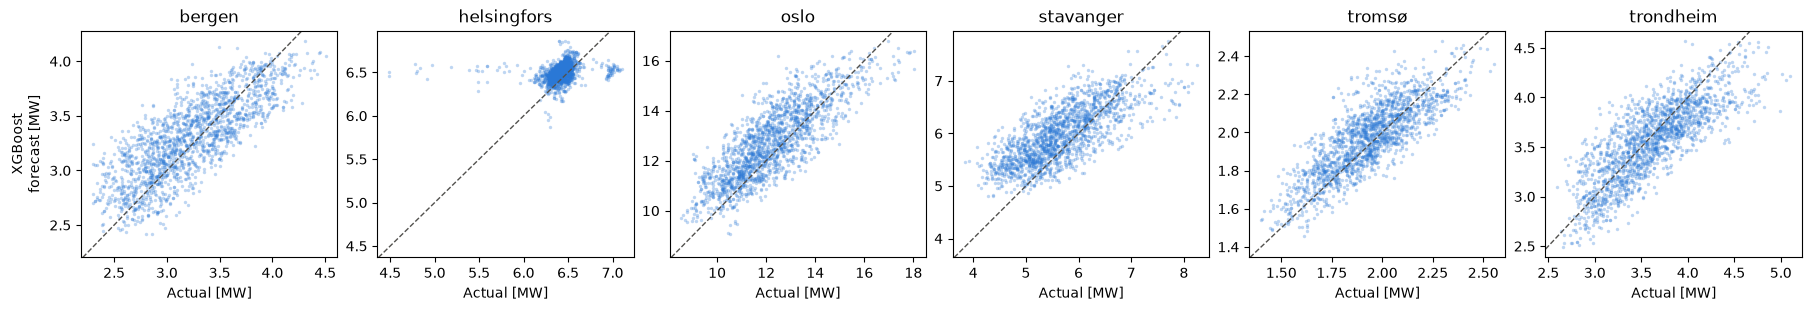

In [13]:
forecastValidator.plot_predicted_vs_actual_consumption(no_baseline=True)

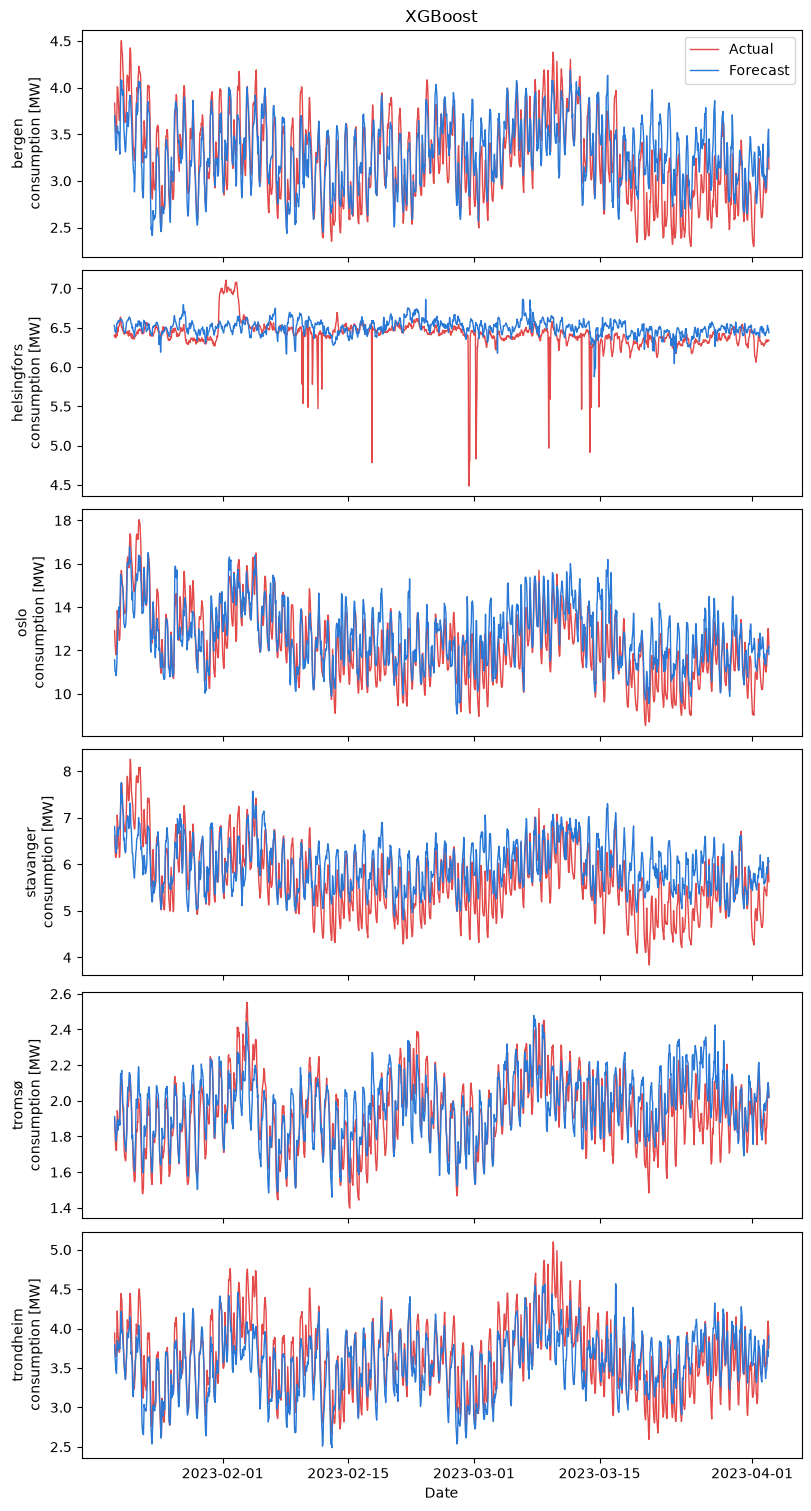

In [14]:
forecastValidator.plot_consumption_over_time(trainer.df.loc[y_test.index, "time"], no_baseline=True)